# Week 6 Examples (Python version) - Bruno Cavagnaro

**GRAD 50800 - Data Analytics**

This is a Python translation of `Week_6_Examples.R`. It covers:
1. Decision Tree
2. Random Forest
3. Support Vector Machine (SVM)
4. Ensemble Learning (majority vote)

**R → Python mapping**

| R | Python |
|---|---|
| `data(iris)` | `sklearn.datasets.load_iris(as_frame=True)` |
| `caret::createDataPartition(p = 0.8)` | `train_test_split(test_size=0.2, stratify=y)` |
| `rpart(method = "class")` | `DecisionTreeClassifier` (with rpart's default stopping rules) |
| `randomForest(ntree = 100)` | `RandomForestClassifier(n_estimators=100)` |
| `e1071::svm()` | `StandardScaler` + `SVC(kernel="rbf")` (e1071 scales the features by default) |
| `apply(..., table/sort)` majority vote | `pandas.DataFrame.mode` / `Counter` |
| `ggplot(...) + geom_bar()` | `matplotlib` bar chart |

The R script also loads `class`, `neuralnet`, `tm` and `SnowballC`, but never uses them, so they have no Python counterpart here.

> **Note:** the R and Python random number generators differ, so `set.seed(42)` and `random_state=42` produce **different** train/test splits. The accuracies will be close to the R output but not identical.

## Setup: libraries and data

In [1]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# data(iris)
iris_raw = load_iris(as_frame=True)
iris = iris_raw.frame.rename(columns={
    "sepal length (cm)": "Sepal.Length", "sepal width (cm)": "Sepal.Width",
    "petal length (cm)": "Petal.Length", "petal width (cm)": "Petal.Width"})
iris["Species"] = iris_raw.target_names[iris.pop("target")]
iris.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Train/test split (80/20, stratified by species)

`createDataPartition(iris$Species, p = 0.8)` samples **within each species**, so the class proportions are the same in train and test. `stratify=y` does the same thing.

In [2]:
SEED = 42                                   # set.seed(42)
X = iris.drop(columns="Species")
y = iris["Species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(pd.concat([y_train.value_counts().rename("train"), y_test.value_counts().rename("test")], axis=1))

Train: (120, 4) | Test: (30, 4)
            train  test
Species                
setosa         40    10
virginica      40    10
versicolor     40    10


## 1. Decision Tree

`rpart` stops splitting according to its defaults: `minsplit = 20` (minimum observations needed to try a split), `minbucket = 7` (minimum observations per leaf, `round(minsplit / 3)`) and `cp = 0.01` (a split must improve fit by at least 1%). I copy the first two with `min_samples_split=20` and `min_samples_leaf=7`. scikit-learn's cost-complexity pruning (`ccp_alpha`) is a different scale from `cp`, so I use a small value to remove splits that improve the tree only trivially. Both libraries use the Gini index for classification.

In [3]:
tree_model = DecisionTreeClassifier(criterion="gini", min_samples_split=20, min_samples_leaf=7,
                                    ccp_alpha=0.01, random_state=SEED)
tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)   # mean(pred == actual)
print("DECISION TREE")
print("Accuracy:", round(tree_accuracy, 4))

DECISION TREE
Accuracy: 0.9333


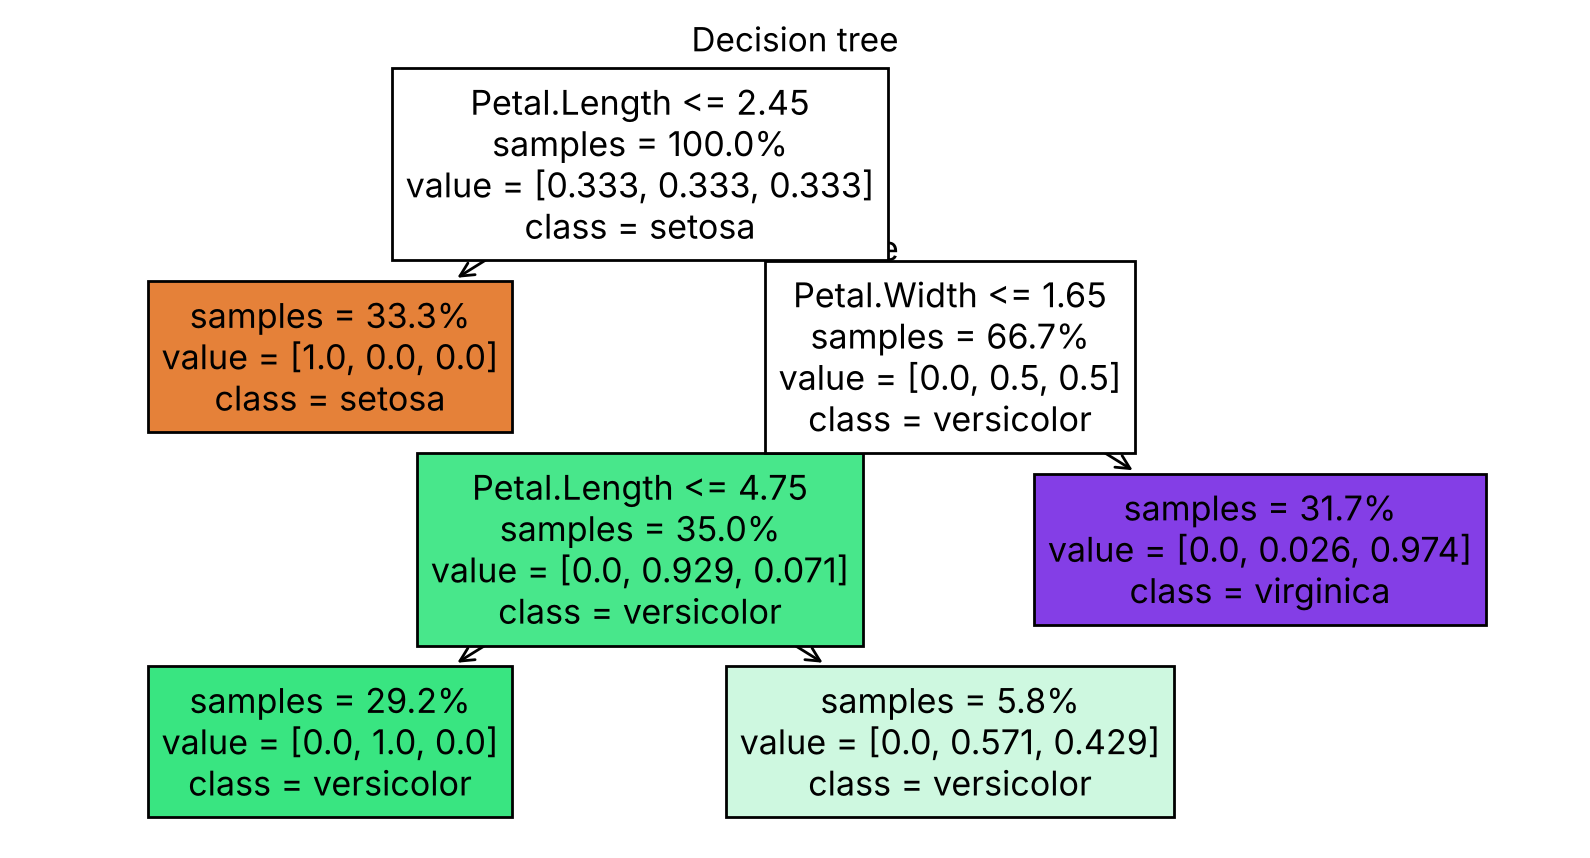

In [4]:
# Like plot(tree_model) / rpart.plot in R
plt.figure(figsize=(10, 5))
plot_tree(tree_model, feature_names=X.columns, class_names=tree_model.classes_,
          filled=True, impurity=False, proportion=True)
plt.title("Decision tree")
plt.show()

## 2. Random Forest

`randomForest(ntree = 100)` grows 100 trees. For classification it tries `mtry = floor(sqrt(p))` features at each split, and grows each tree fully (`nodesize = 1`). scikit-learn's defaults (`max_features="sqrt"`, `min_samples_leaf=1`) match.

In [5]:
rf_model = RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=SEED)
rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)
print("RANDOM FOREST")
print("Accuracy:", round(rf_accuracy, 4))

# Extra: variable importance (like importance(rf_model) in R)
pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).round(3)

RANDOM FOREST
Accuracy: 0.9


Petal.Width     0.437
Petal.Length    0.431
Sepal.Length    0.116
Sepal.Width     0.015
dtype: float64

## 3. Support Vector Machine

The `e1071::svm()` defaults for a factor outcome are a C-classification SVM with a **radial (RBF) kernel**, `cost = 1`, `gamma = 1 / (number of features)` and **standardised features** (`scale = TRUE`). The Python version uses a pipeline of `StandardScaler` and `SVC(kernel="rbf", C=1, gamma=1/4)`. Like e1071 (libsvm), `SVC` handles more than two classes with one-vs-one voting.

In [6]:
svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=1 / X_train.shape[1]))
svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)
print("SVM")
print("Accuracy:", round(svm_accuracy, 4))

SVM
Accuracy: 0.9667


## 4. Ensemble Learning (majority vote)

Each test flower gets three votes (tree, forest, SVM), and the most common class wins. In R, `names(sort(table(x), decreasing = TRUE))[1]` breaks a three-way tie by taking the alphabetically first class, because `table()` orders its names alphabetically and the sort keeps that order among ties. The function below does the same.

In [7]:
ensemble_votes = pd.DataFrame({"Tree": tree_predictions,
                               "Forest": rf_predictions,
                               "SVM": svm_predictions}, index=y_test.index)

def majority(row):
    counts = Counter(row)
    top = max(counts.values())
    return sorted(k for k, v in counts.items() if v == top)[0]   # R-style tie-break

majority_vote = ensemble_votes.apply(majority, axis=1)
ensemble_accuracy = accuracy_score(y_test, majority_vote)
print("ENSEMBLE LEARNING")
print("Ensemble Accuracy:", round(ensemble_accuracy, 4))

# Extra: the test cases where the three models disagree
disagree = ensemble_votes.nunique(axis=1) > 1
display(ensemble_votes[disagree].assign(Majority=majority_vote[disagree], Actual=y_test[disagree]))

ENSEMBLE LEARNING
Ensemble Accuracy: 0.9333


,Tree,Forest,SVM,Majority,Actual
138,virginica,versicolor,virginica,virginica,virginica
134,versicolor,versicolor,virginica,versicolor,virginica


## Model comparison

In [8]:
results = pd.DataFrame({"Model": ["Decision Tree", "Random Forest", "SVM"],
                        "Accuracy": [tree_accuracy, rf_accuracy, svm_accuracy]})
print(results)

           Model  Accuracy
0  Decision Tree  0.933333
1  Random Forest  0.900000
2            SVM  0.966667


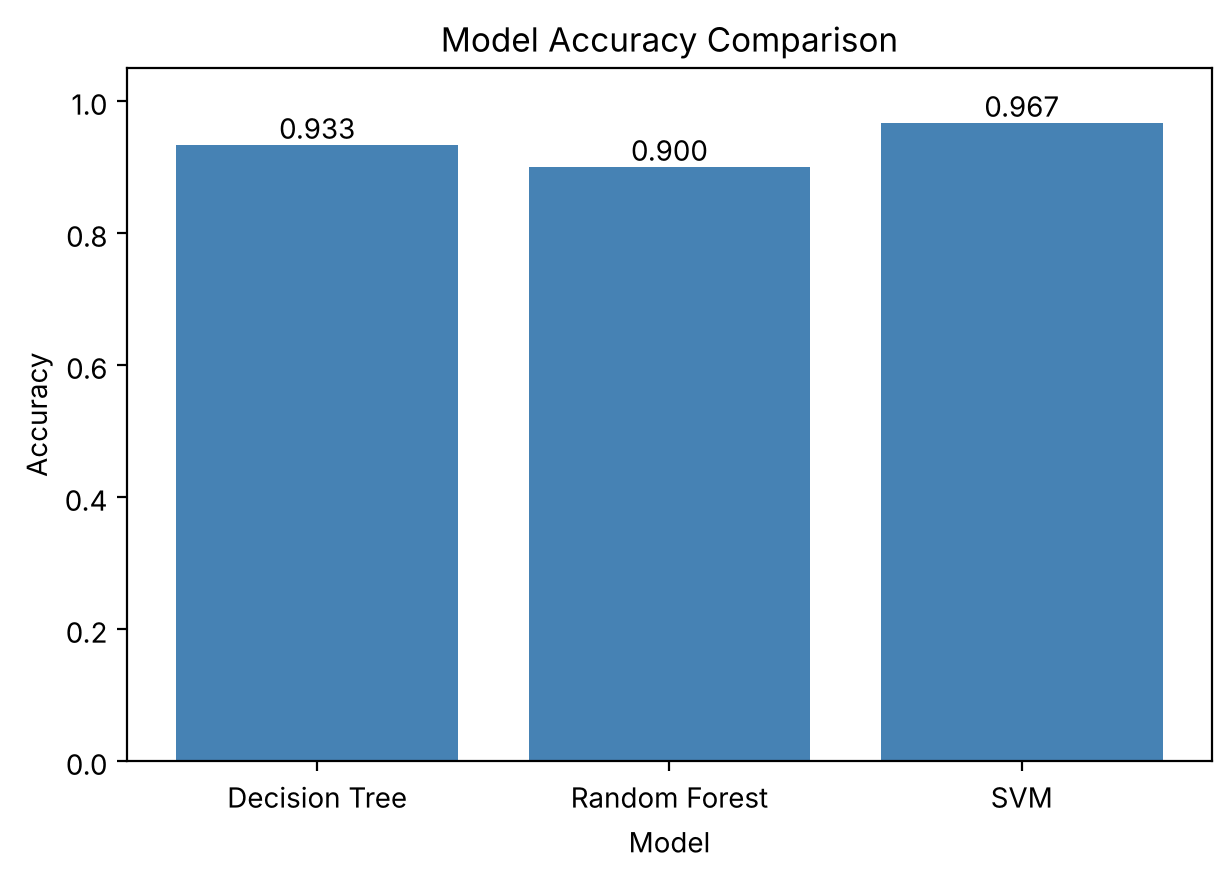

WEEK 6 EXAMPLES COMPLETE


In [9]:
# ggplot(results, aes(Model, Accuracy)) + geom_bar(stat = "identity", fill = "steelblue")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(results["Model"], results["Accuracy"], color="steelblue")
for i, acc in enumerate(results["Accuracy"]):
    ax.text(i, acc + 0.01, f"{acc:.3f}", ha="center")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Model"); ax.set_ylabel("Accuracy")
ax.set_title("Model Accuracy Comparison")
plt.show()

print("WEEK 6 EXAMPLES COMPLETE")

### Notes
* Iris is an easy dataset: all three models usually score 90-100% on 30 test flowers. Each flower is 3.3 accuracy points, so differences of one or two flowers between models (or between R and Python) are noise, not evidence that one method is better.
* The majority vote helps only when the models make **different** mistakes. In this split the ensemble (93.3%) is actually *worse* than the SVM (96.7%). On flower 134, the tree and the forest both said versicolor and outvoted the SVM's correct virginica (see the disagreement table). An equal-weight vote helps only when the models are similarly accurate and make different errors. Otherwise, weighting each model's vote by its cross-validated accuracy, or stacking, works better.
* For a more reliable comparison, use repeated k-fold cross-validation (`cross_val_score`, the equivalent of `caret::train(trControl = trainControl("repeatedcv"))`) instead of a single 80/20 split.